In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("C:\\Users\\ahama\\OneDrive\\Documents\\New folder\\Exp-1.csv")
df

,Input,Output
0,1,2
1,2,4
2,3,6
3,4,8
4,5,10
5,6,12
6,7,14
7,8,16
8,9,18
9,10,20


In [3]:
x=df[["Input"]].values
y=df[["Output"]].values

In [4]:
xt,xst,yt,yst=train_test_split(x,y,test_size=0.33,random_state=33)

In [5]:
scaler1=MinMaxScaler()
scaler2=MinMaxScaler()
xt=scaler1.fit_transform(xt)
xst=scaler2.fit_transform(xst)

In [6]:
xt1=torch.FloatTensor(xt)
xst1=torch.FloatTensor(xst)
yt1=torch.FloatTensor(yt)
yst1=torch.FloatTensor(yst)

In [7]:
class neuralnet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network=nn.Sequential(
          nn.Linear(1,20),
          nn.ReLU(),
          nn.Linear(20,10),
          nn.ReLU(),
          nn.Linear(10,1)
        )
    def forward(self,x):
        return self.network(x)

In [8]:
model=neuralnet()
criterion=nn.MSELoss()
optimizer=optim.Adam(model.parameters(),lr=0.001)

In [9]:
epochs=1000
loss_list=[]
for i in range(epochs):
    optimizer.zero_grad()
    pred=model(xt1)
    loss=criterion(pred,yt1)
    loss.backward()
    optimizer.step()
    if i%100==0:
        print(f"epochs: {i} / {epochs} loss:",loss.item())
        loss_list.append(loss.item())
        
        

epochs: 0 / 1000 loss: 294.3172302246094
epochs: 100 / 1000 loss: 263.0892639160156
epochs: 200 / 1000 loss: 200.8356170654297
epochs: 300 / 1000 loss: 91.95466613769531
epochs: 400 / 1000 loss: 21.62795639038086
epochs: 500 / 1000 loss: 10.416855812072754
epochs: 600 / 1000 loss: 8.693111419677734
epochs: 700 / 1000 loss: 7.250882625579834
epochs: 800 / 1000 loss: 5.928953170776367
epochs: 900 / 1000 loss: 4.74362850189209


with torch.no_grad():
    pred=model(xst)
    loss=criterion(pred,yst)
    print(loss.item())

In [10]:
with torch.no_grad():
    pred=model(xst1)
    loss=criterion(pred,yst1)
    print(loss.item())

35.347938537597656


In [11]:
input=torch.FloatTensor(scaler1.transform([[18]]))
pred=model(input)
print(pred.item())

30.431432723999023


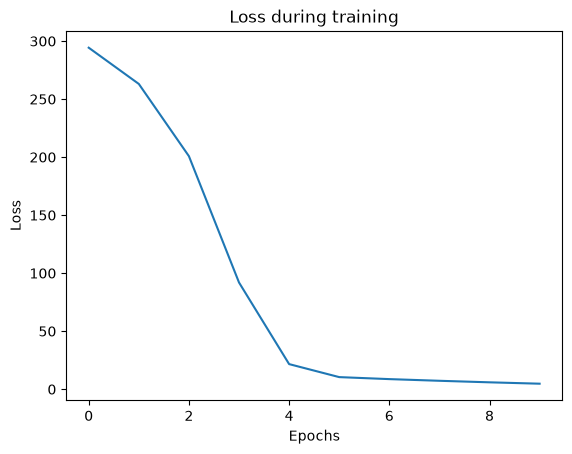

In [12]:
plt.plot(loss_list)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss during training")
plt.show()